# Practice 2 — Product Sales Prediction

Notebook thực hành cho dự án dự đoán doanh thu giao dịch sản phẩm bằng Machine Learning.

**Workflow:** Problem Definition → Data Loading → EDA → Data Cleaning → Chronological Split → Feature Engineering → Model Training → Hyperparameter Tuning → Evaluation → Save Model → Local Prediction.

> Notebook gọi lại các module trong `src/` để kết quả và quy trình thống nhất với chương trình `run_pipeline.py`. Notebook được cung cấp ở trạng thái chưa thực thi; hãy chạy từ trên xuống trong môi trường đã cài `requirements.txt` để tạo output trên máy của bạn.


## 1. Problem Definition

Đây là bài toán **Supervised Learning — Regression**. Mục tiêu là dự đoán doanh thu của một giao dịch:

```python
sales = unit_price * quantity
```

`quantity` tham gia tính Target nhưng được loại khỏi Feature DataFrame cuối cùng. Đây là lựa chọn thiết kế để hạn chế mô hình học lại trực tiếp công thức tạo Target. Do đó, mô hình hiện tại không được dùng cho tình huống đã biết một số lượng đặt trước và cần tính tổng doanh thu tương ứng.


## 2. Environment and Imports

Notebook cần được mở bên trong repository `ML_Lab2/`. Đoạn code dưới đây tìm thư mục gốc từ thư mục làm việc hiện tại, kể cả khi kernel đang chạy từ `notebooks/`.


In [3]:
from pathlib import Path
import os
import sys
import json

import numpy as np
import pandas as pd
from IPython.display import display, Image

# Find the project root by locating the src/ and data/ directories.
current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [current, *current.parents]
     if (path / "src").is_dir() and (path / "data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục gốc ML_Lab2. Hãy mở notebook bên trong repository."
    )
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)


Project root: /Users/momo/Downloads/ML_Lab2


In [4]:
from src.data_collection import collect_data
from src.eda import perform_eda
from src.data_preprocessing import preprocess_data
from src.feature_engineering import engineer_features
from src.training import train_models
from src.eval import evaluate_models
from src.report import write_report
from src.inference import predict_sales

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "sales_data.csv"
assert RAW_DATA_PATH.exists(), f"Không tìm thấy dataset: {RAW_DATA_PATH}"


## 3. Data Collection and Loading

Dữ liệu nguồn nằm tại `data/raw/sales_data.csv`. Module `collect_data()` chuẩn bị dữ liệu nguồn theo pipeline hiện tại. Sau đó Pandas được sử dụng để đọc CSV thành DataFrame.


In [5]:
collect_data()

raw_df = pd.read_csv(RAW_DATA_PATH)
print("Dataset shape:", raw_df.shape)
display(raw_df.head())


✅ Đã thu thập và lưu dữ liệu thành công tại: data/raw/sales_data.csv
📊 Kích thước dữ liệu: 500 dòng, 11 cột
Dataset shape: (500, 11)


,order_id,customer_id,product_id,product_name,category,unit_price,quantity,order_date,customer_age,customer_gender,country
0,1,150,9,Tablet,Electronics,611,1,11/14/2022,62,Female,Germany
1,2,176,36,Smartphone,Electronics,751,4,10/6/2022,23,Male,Canada
2,3,37,22,Jacket,Accessories,821,4,5/7/2022,54,Male,UK
3,4,143,42,Shoes,Electronics,395,4,5/9/2022,50,Male,Germany
4,5,163,26,Jacket,Accessories,301,1,2/27/2022,39,Male,Australia


### 3.1. Understand the Dataset

Mỗi dòng biểu diễn một giao dịch. Các cột bao gồm mã đơn hàng, khách hàng, sản phẩm, danh mục, đơn giá, số lượng, ngày giao dịch và thông tin khách hàng.


In [6]:
raw_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   order_id         500 non-null    int64 
 1   customer_id      500 non-null    int64 
 2   product_id       500 non-null    int64 
 3   product_name     500 non-null    object
 4   category         500 non-null    object
 5   unit_price       500 non-null    int64 
 6   quantity         500 non-null    int64 
 7   order_date       500 non-null    object
 8   customer_age     500 non-null    int64 
 9   customer_gender  500 non-null    object
 10  country          500 non-null    object
dtypes: int64(6), object(5)
memory usage: 43.1+ KB


In [7]:
missing_summary = raw_df.isna().sum().rename("missing_count").to_frame()
missing_summary["missing_percent"] = (missing_summary["missing_count"] / len(raw_df) * 100).round(2)
display(missing_summary)

print("Duplicate rows:", int(raw_df.duplicated().sum()))


,missing_count,missing_percent
order_id,0,0.0
customer_id,0,0.0
product_id,0,0.0
product_name,0,0.0
category,0,0.0
unit_price,0,0.0
quantity,0,0.0
order_date,0,0.0
customer_age,0,0.0
customer_gender,0,0.0


Duplicate rows: 0


### 3.2. Define the Target

Target `sales` được tính từ đơn giá nhân với số lượng. Đây là doanh thu của một giao dịch, không phải số lượng sản phẩm bán ra.


In [8]:
analysis_df = raw_df.copy()
analysis_df["order_date"] = pd.to_datetime(
    analysis_df["order_date"], errors="coerce", format="mixed"
)
analysis_df["sales"] = (
    pd.to_numeric(analysis_df["unit_price"], errors="coerce")
    * pd.to_numeric(analysis_df["quantity"], errors="coerce")
)

display(analysis_df[["unit_price", "quantity", "sales"]].head())
display(analysis_df["sales"].describe().to_frame().T)


,unit_price,quantity,sales
0,611,1,611
1,751,4,3004
2,821,4,3284
3,395,4,1580
4,301,1,301


,count,mean,std,min,25%,50%,75%,max
sales,500.0,1463.58,1004.789843,51.0,611.0,1262.0,2059.0,3968.0


## 4. Exploratory Data Analysis (EDA)

EDA giúp hiểu phân phối Target và quan sát doanh thu theo danh mục, quốc gia, tháng cũng như mối quan hệ giữa đơn giá và doanh thu. Module `src/eda.py` lưu các biểu đồ vào `figures/`.


In [9]:
eda_summary = perform_eda()
display(pd.Series(eda_summary, name="value").to_frame())


EDA complete: /Users/momo/Downloads/ML_Lab2/figures
Rows=500, duplicate rows=0, missing=0


,value
rows,500
columns,12
missing_values,"{'order_id': 0, 'customer_id': 0, 'product_id'..."
duplicate_rows,0
sales_mean,1463.58
sales_median,1262.0
sales_min,51.0
sales_max,3968.0
date_min,2022-01-01
date_max,2022-12-31


eda_sales_distribution.png


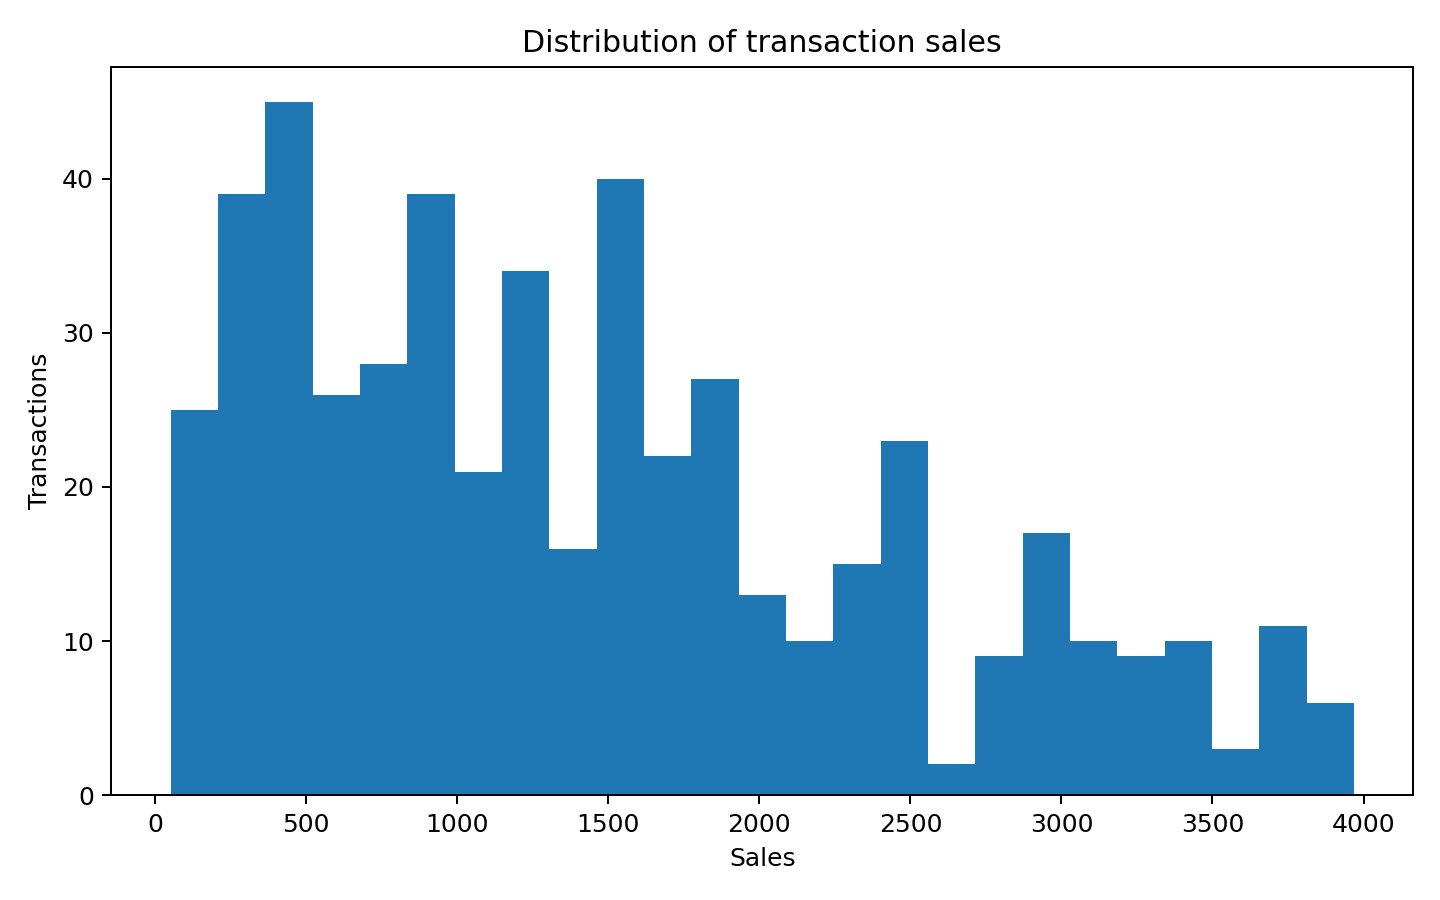

eda_sales_by_category.png


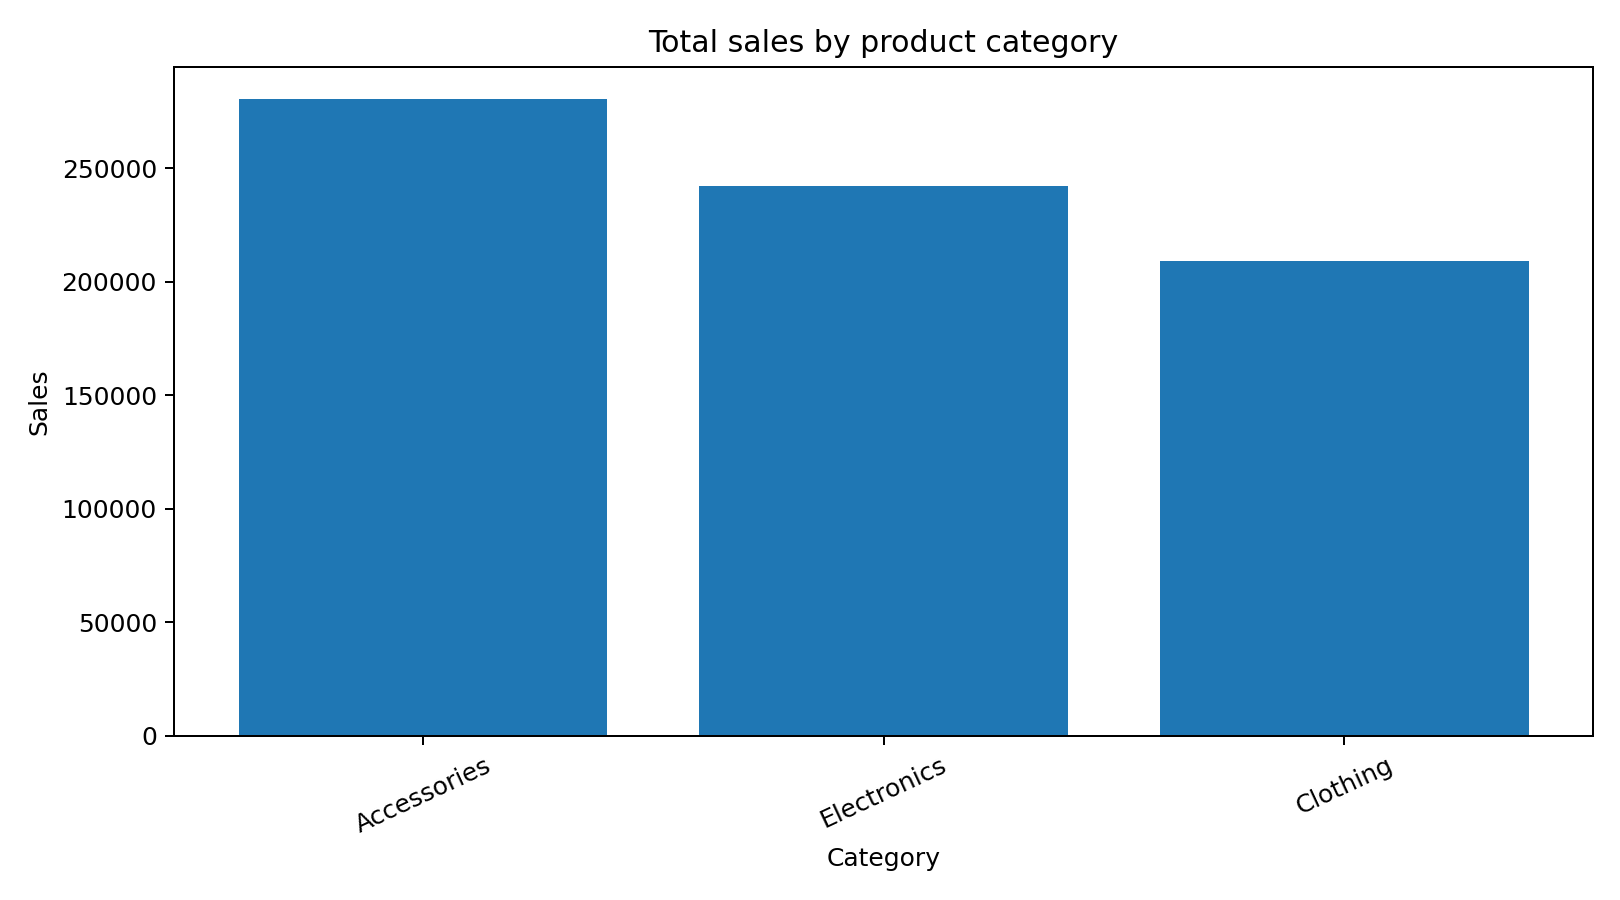

eda_sales_by_country.png


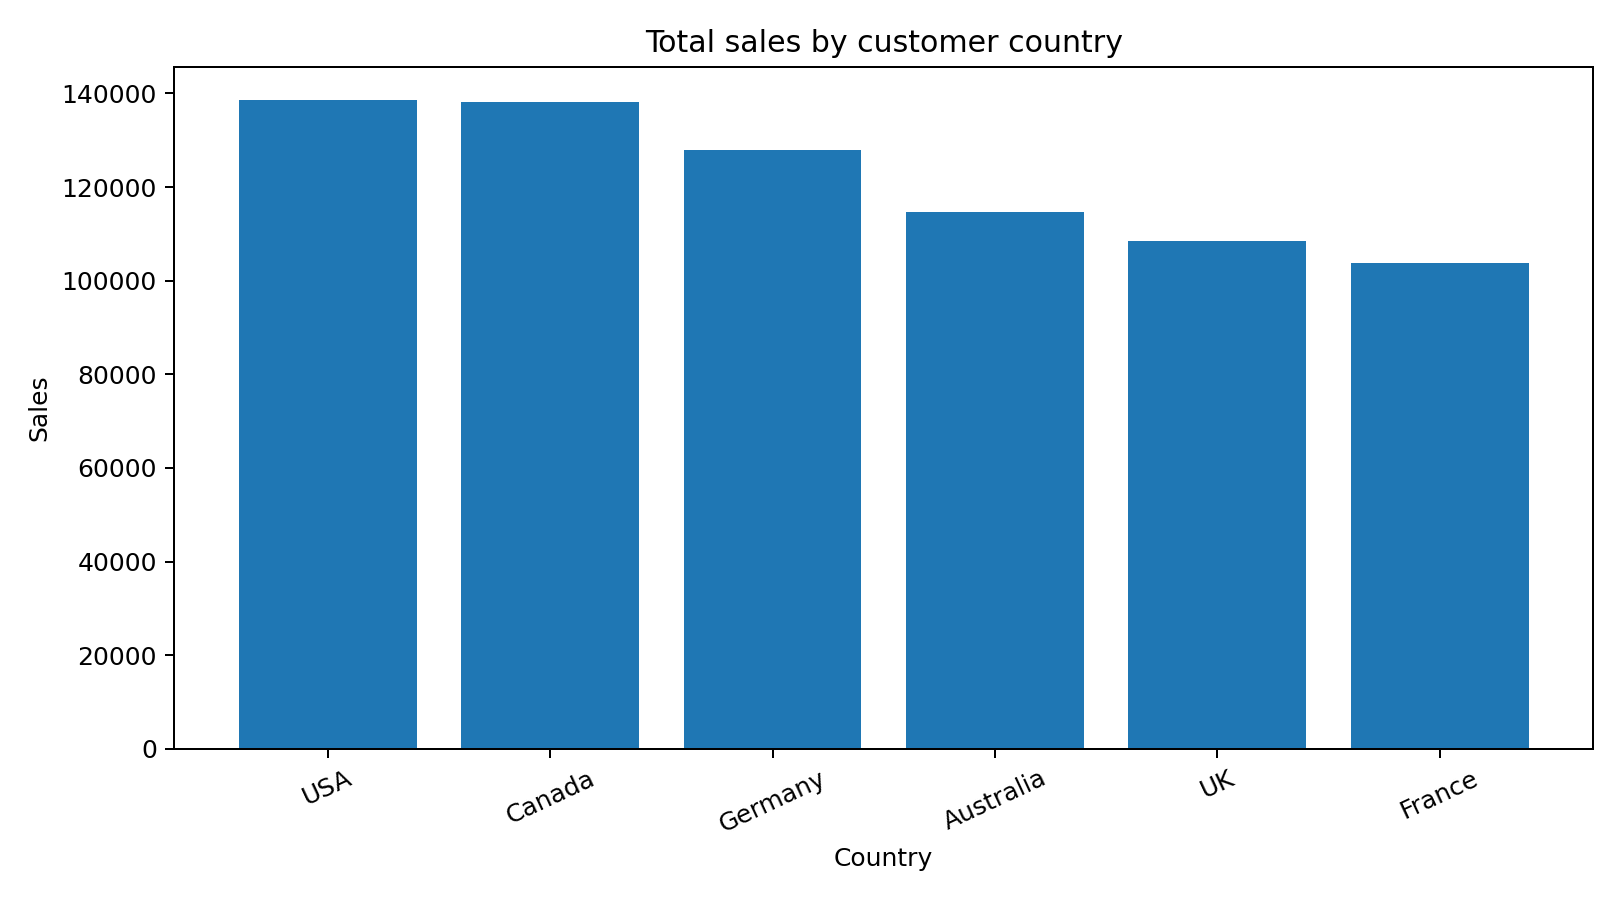

eda_monthly_sales_trend.png


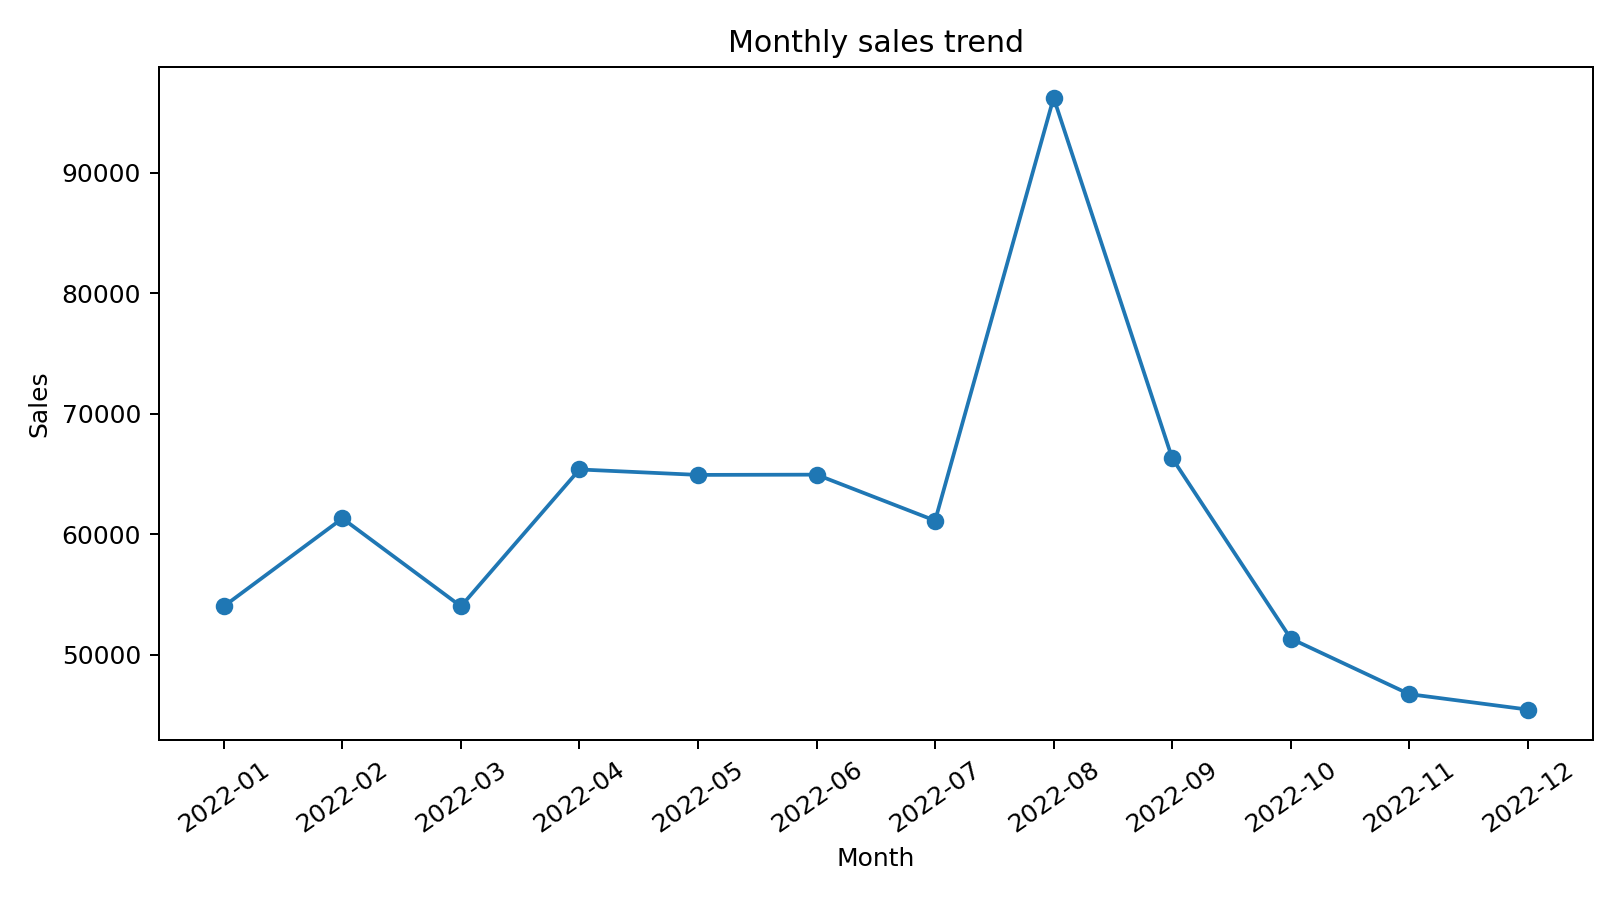

eda_price_vs_sales.png


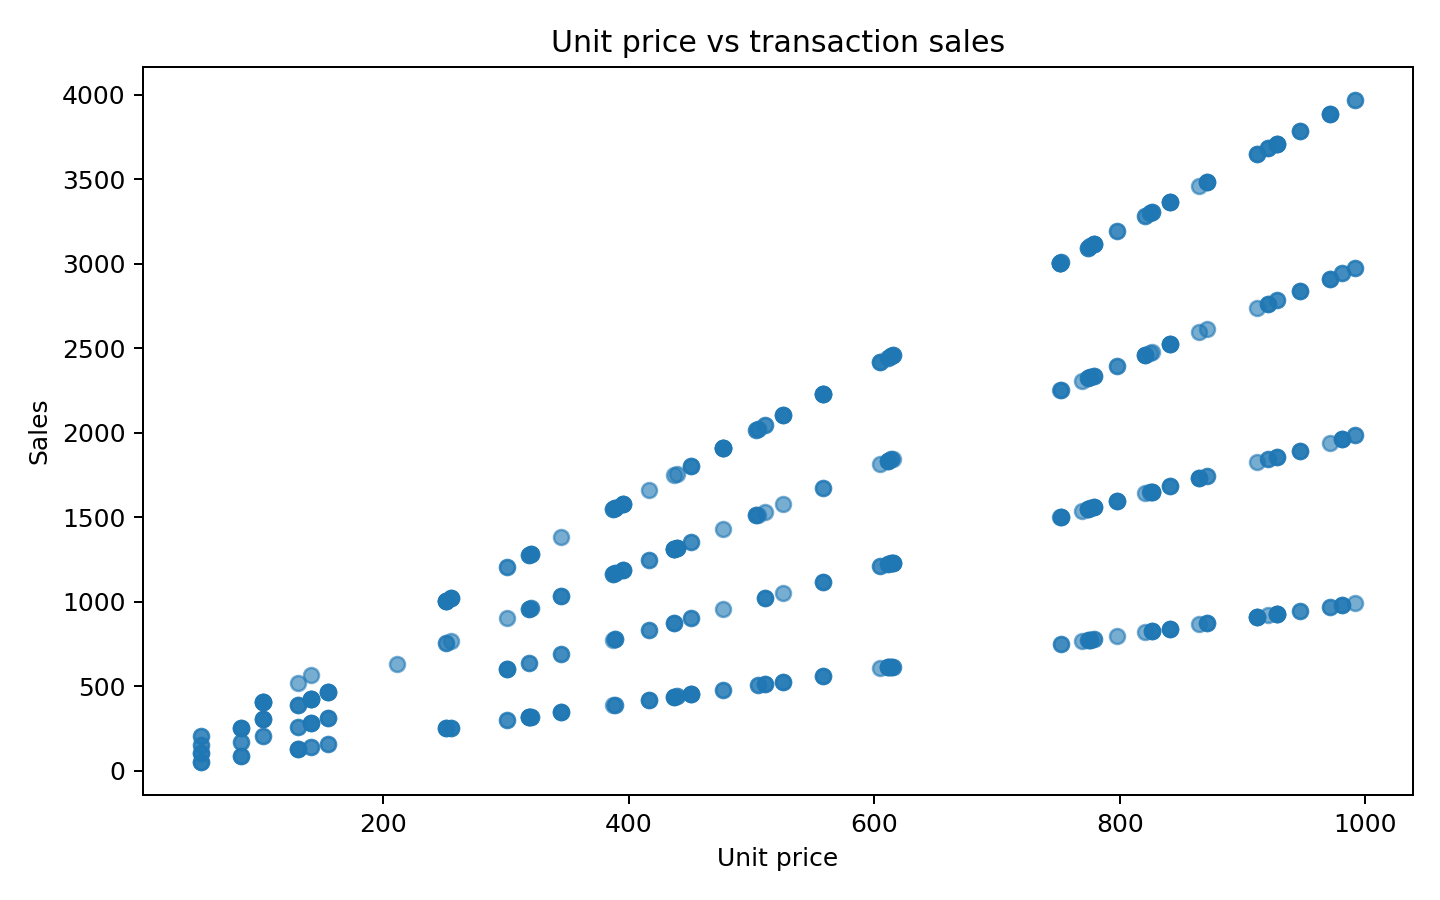

In [10]:
eda_figure_names = [
    "eda_sales_distribution.png",
    "eda_sales_by_category.png",
    "eda_sales_by_country.png",
    "eda_monthly_sales_trend.png",
    "eda_price_vs_sales.png",
]

for figure_name in eda_figure_names:
    figure_path = PROJECT_ROOT / "figures" / figure_name
    if figure_path.exists():
        print(figure_name)
        display(Image(filename=str(figure_path)))


## 5. Data Preprocessing

Module `src/data_preprocessing.py` thực hiện parse ngày, chuyển kiểu dữ liệu, loại bản ghi trùng/không hợp lệ, tạo Target, chia Train/Test theo ngày và giới hạn ngoại lệ của biến đầu vào bằng ngưỡng IQR chỉ tính từ Train.

Tập Test chứa các giao dịch ở thời điểm sau tập Train. Đây là cách chia phù hợp hơn với mục tiêu mô phỏng dự đoán giao dịch tương lai.


In [11]:
preprocessing_summary = preprocess_data()
display(pd.Series(preprocessing_summary, name="value").to_frame())


Prepared 409 training rows and 91 later-date test rows.
Target: sales = unit_price * quantity; quantity excluded from X.
Saved processed data to: /Users/momo/Downloads/ML_Lab2/data/processed


,value
original_rows,500
clean_rows,500
rows_removed_during_cleaning,0
missing_values_after_cleaning,"{'order_id': 0, 'customer_id': 0, 'product_id'..."
target_definition,sales = unit_price * quantity
date_min,2022-01-01
date_max,2022-12-31
train_rows,409
test_rows,91
train_max_date,2022-10-12


In [12]:
processed_dir = PROJECT_ROOT / "data" / "processed"
train_base = pd.read_csv(processed_dir / "train_base.csv")
test_base = pd.read_csv(processed_dir / "test_base.csv")
y_train = pd.read_csv(processed_dir / "y_train.csv")["sales"]
y_test = pd.read_csv(processed_dir / "y_test.csv")["sales"]

train_end = pd.to_datetime(train_base["order_date"]).max()
test_start = pd.to_datetime(test_base["order_date"]).min()

split_check = {
    "train_rows": len(train_base),
    "test_rows": len(test_base),
    "train_end_date": str(train_end.date()),
    "test_start_date": str(test_start.date()),
    "chronological_order_is_valid": bool(train_end < test_start),
}
display(pd.Series(split_check, name="value").to_frame())
assert train_end < test_start, "Train và Test đang bị chồng lấn thời gian."


,value
train_rows,409
test_rows,91
train_end_date,2022-10-12
test_start_date,2022-10-13
chronological_order_is_valid,True


### 5.1. Understanding X and y

- `X` là các Feature dùng làm đầu vào cho mô hình.
- `y` là Target mà mô hình cần dự đoán, ở đây là `sales`.
- `X_train` và `y_train` dùng để huấn luyện/tuning.
- `X_test` và `y_test` dùng để đánh giá cuối cùng.

Ở bước dữ liệu nền, `train_base.csv` và `test_base.csv` vẫn giữ thông tin nguồn để Feature Engineering có thể sử dụng. `quantity` không được đưa vào Feature DataFrame cuối cùng do hàm `engineer_dataframe()` chỉ chọn các cột đầu vào hợp lệ.


## 6. Feature Engineering

Module `src/feature_engineering.py` tạo các đặc trưng lịch sử và thời gian.

- Product history: số giao dịch trước đó và doanh thu trung bình trước đó của sản phẩm.
- Customer history: tần suất giao dịch, tổng doanh thu lịch sử và doanh thu trung bình lịch sử của khách hàng.
- Calendar: tháng, quý, thứ trong tuần, cuối tuần.
- Seasonality: proxy mùa cao điểm tháng 11–12 và các đặc trưng mã hóa chu kỳ.

Điểm quan trọng: với mỗi giao dịch, hệ thống đọc lịch sử trước, tạo Feature, rồi mới cập nhật lịch sử bằng Target của giao dịch Train đó. Test sử dụng lịch sử Train ở chế độ chỉ đọc.


In [13]:
feature_history = engineer_features()
X_train_fe = pd.read_csv(processed_dir / "X_train_fe.csv")
X_test_fe = pd.read_csv(processed_dir / "X_test_fe.csv")

print("X_train_fe shape:", X_train_fe.shape)
print("X_test_fe shape:", X_test_fe.shape)
print("Number of feature columns:", len(X_train_fe.columns))
display(X_train_fe.head())


Engineered 22 features; quantity and current target are excluded.
History features use previous training transactions only.
X_train_fe shape: (409, 22)
X_test_fe shape: (91, 22)
Number of feature columns: 22


,product_id,product_name,category,customer_id,customer_gender,country,unit_price,customer_age,product_popularity_prior,product_avg_sales_prior,...,customer_avg_sales_prior,month,quarter,day_of_week,is_weekend,is_holiday_season,month_sin,month_cos,day_of_year_sin,day_of_year_cos
0,17,Camera,Clothing,160,Female,Australia,251,23.0,0,0.0,...,0.0,1,1,5,1,0,0.5,0.866025,0.017202,0.999852
1,7,Sunglasses,Electronics,134,Male,UK,320,60.0,0,0.0,...,0.0,1,1,5,1,0,0.5,0.866025,0.017202,0.999852
2,48,Watch,Electronics,97,Male,UK,971,32.0,0,0.0,...,0.0,1,1,5,1,0,0.5,0.866025,0.017202,0.999852
3,43,Sunglasses,Electronics,58,Female,Australia,301,50.0,0,0.0,...,0.0,1,1,5,1,0,0.5,0.866025,0.017202,0.999852
4,16,Sunglasses,Accessories,168,Male,France,84,54.0,0,0.0,...,0.0,1,1,5,1,0,0.5,0.866025,0.017202,0.999852


In [14]:
# Validate that the target and quantity are not model input features.
assert "sales" not in X_train_fe.columns
assert "quantity" not in X_train_fe.columns
assert "sales" not in X_test_fe.columns
assert "quantity" not in X_test_fe.columns
assert list(X_train_fe.columns) == list(X_test_fe.columns)

print("Leakage checks passed: no sales/quantity columns in final X.")
print("Feature columns:")
for feature_name in X_train_fe.columns:
    print("-", feature_name)


Leakage checks passed: no sales/quantity columns in final X.
Feature columns:
- product_id
- product_name
- category
- customer_id
- customer_gender
- country
- unit_price
- customer_age
- product_popularity_prior
- product_avg_sales_prior
- customer_purchase_frequency
- customer_lifetime_value_prior
- customer_avg_sales_prior
- month
- quarter
- day_of_week
- is_weekend
- is_holiday_season
- month_sin
- month_cos
- day_of_year_sin
- day_of_year_cos


## 7. Model Training and Hyperparameter Tuning

Dự án so sánh:

1. Linear Regression — baseline tuyến tính.
2. Decision Tree Regressor — mô hình cây đơn.
3. Random Forest Regressor — ensemble nhiều cây.
4. Gradient Boosting Regressor — ensemble xây dựng tuần tự.
5. Dummy Mean — baseline dự đoán trung bình.

Các mô hình cây sử dụng `GridSearchCV` và `TimeSeriesSplit(n_splits=3)`. Điểm chọn mô hình là CV MAE thấp nhất trên tập Train.


In [15]:
training_summary = train_models()
display(pd.Series(training_summary, name="value").to_frame())


Training LinearRegression...
  CV MAE=788.720; test MAE=671.922; params={}
Training DecisionTree...
  CV MAE=688.720; test MAE=743.484; params={'model__max_depth': 5, 'model__min_samples_leaf': 3}
Training RandomForest...
  CV MAE=611.947; test MAE=648.820; params={'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Training GradientBoosting...
  CV MAE=619.449; test MAE=653.421; params={'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 100}

Test-set comparison:
           model     MAE        MSE    RMSE     R2  CV_MAE
    RandomForest 648.820 649599.435 805.977  0.286 611.947
GradientBoosting 653.421 625917.931 791.150  0.312 619.449
    DecisionTree 743.484 960512.335 980.057 -0.056 688.720
LinearRegression 671.922 698524.060 835.778  0.232 788.720
       DummyMean 811.340 945125.931 972.176 -0.039 854.401

Selected RandomForest based on time-series cross-validation MAE.
Saved model bundle: /Users/momo/Downloads/ML_Lab2/models

,value
best_model,RandomForest
selection_basis,lowest time-series CV MAE
best_model_test_metrics,"{'model': 'RandomForest', 'MAE': 648.819816253..."
models_compared,"[LinearRegression, DecisionTree, RandomForest,..."


### 7.1. Compare Model Metrics

Các chỉ số được lưu trong `models/metrics.csv`. MAE, MSE và RMSE đo độ lớn sai số; R² đo mức độ giải thích biến thiên của Target; CV_MAE là MAE trung bình trên các fold thời gian của Train.


In [16]:
metrics_path = PROJECT_ROOT / "models" / "metrics.csv"
metrics_df = pd.read_csv(metrics_path).sort_values("CV_MAE").reset_index(drop=True)
display(metrics_df.round(4))


,model,MAE,MSE,RMSE,R2,CV_MAE
0,RandomForest,648.8198,649599.4352,805.9773,0.2857,611.9466
1,GradientBoosting,653.4212,625917.9312,791.1498,0.3117,619.4489
2,DecisionTree,743.4835,960512.3346,980.0573,-0.0562,688.7202
3,LinearRegression,671.9223,698524.0605,835.7775,0.2319,788.7200
4,DummyMean,811.3395,945125.9309,972.1759,-0.0393,854.4013


### 7.2. Inspect Hyperparameter Search

`models/tuning_results.csv` ghi lại các tổ hợp tham số đã được thử nghiệm và CV MAE tương ứng. File này giúp truy vết vì sao một cấu hình được chọn.


In [17]:
tuning_path = PROJECT_ROOT / "models" / "tuning_results.csv"
if tuning_path.exists():
    tuning_df = pd.read_csv(tuning_path)
    display(tuning_df.round(4))
else:
    print("Chưa tìm thấy tuning_results.csv")


,model,params,CV_MAE,CV_MAE_std
0,DecisionTree,"{""model__max_depth"": null, ""model__min_samples...",740.2059,44.0059
1,DecisionTree,"{""model__max_depth"": null, ""model__min_samples...",723.5488,11.4065
2,DecisionTree,"{""model__max_depth"": 5, ""model__min_samples_le...",711.5424,56.0699
3,DecisionTree,"{""model__max_depth"": 5, ""model__min_samples_le...",688.7202,31.3543
4,DecisionTree,"{""model__max_depth"": 10, ""model__min_samples_l...",734.1548,45.0806
5,DecisionTree,"{""model__max_depth"": 10, ""model__min_samples_l...",724.5282,12.3375
6,RandomForest,"{""model__max_depth"": null, ""model__min_samples...",613.2543,16.9448
7,RandomForest,"{""model__max_depth"": null, ""model__min_samples...",615.7214,12.7360
8,RandomForest,"{""model__max_depth"": 10, ""model__min_samples_l...",611.9466,15.6094
9,RandomForest,"{""model__max_depth"": 10, ""model__min_samples_l...",616.1073,12.6905


## 8. Final Evaluation

Sau khi training, module `src/eval.py` tải các model đã lưu và đánh giá trên tập Test theo thời gian. Kết quả được ghi lại trong `models/evaluation_metrics.csv`.


In [18]:
evaluation_df = evaluate_models()
display(evaluation_df.round(4))


           model     MAE        MSE    RMSE     R2
    RandomForest 648.820 649599.435 805.977  0.286
GradientBoosting 653.421 625917.931 791.150  0.312
LinearRegression 671.922 698524.060 835.778  0.232
    DecisionTree 743.484 960512.335 980.057 -0.056
       DummyMean 811.340 945125.931 972.176 -0.039


,model,MAE,MSE,RMSE,R2
4,RandomForest,648.8198,649599.4352,805.9773,0.2857
2,GradientBoosting,653.4212,625917.9312,791.1498,0.3117
3,LinearRegression,671.9223,698524.0605,835.7775,0.2319
0,DecisionTree,743.4835,960512.3346,980.0573,-0.0562
1,DummyMean,811.3395,945125.9309,972.1759,-0.0393


### 8.1. Actual vs Predicted

Biểu đồ so sánh doanh thu thực tế và doanh thu dự đoán. Các điểm càng gần đường chéo tham chiếu thì dự đoán càng gần giá trị thực tế.


model_comparison_mae.png


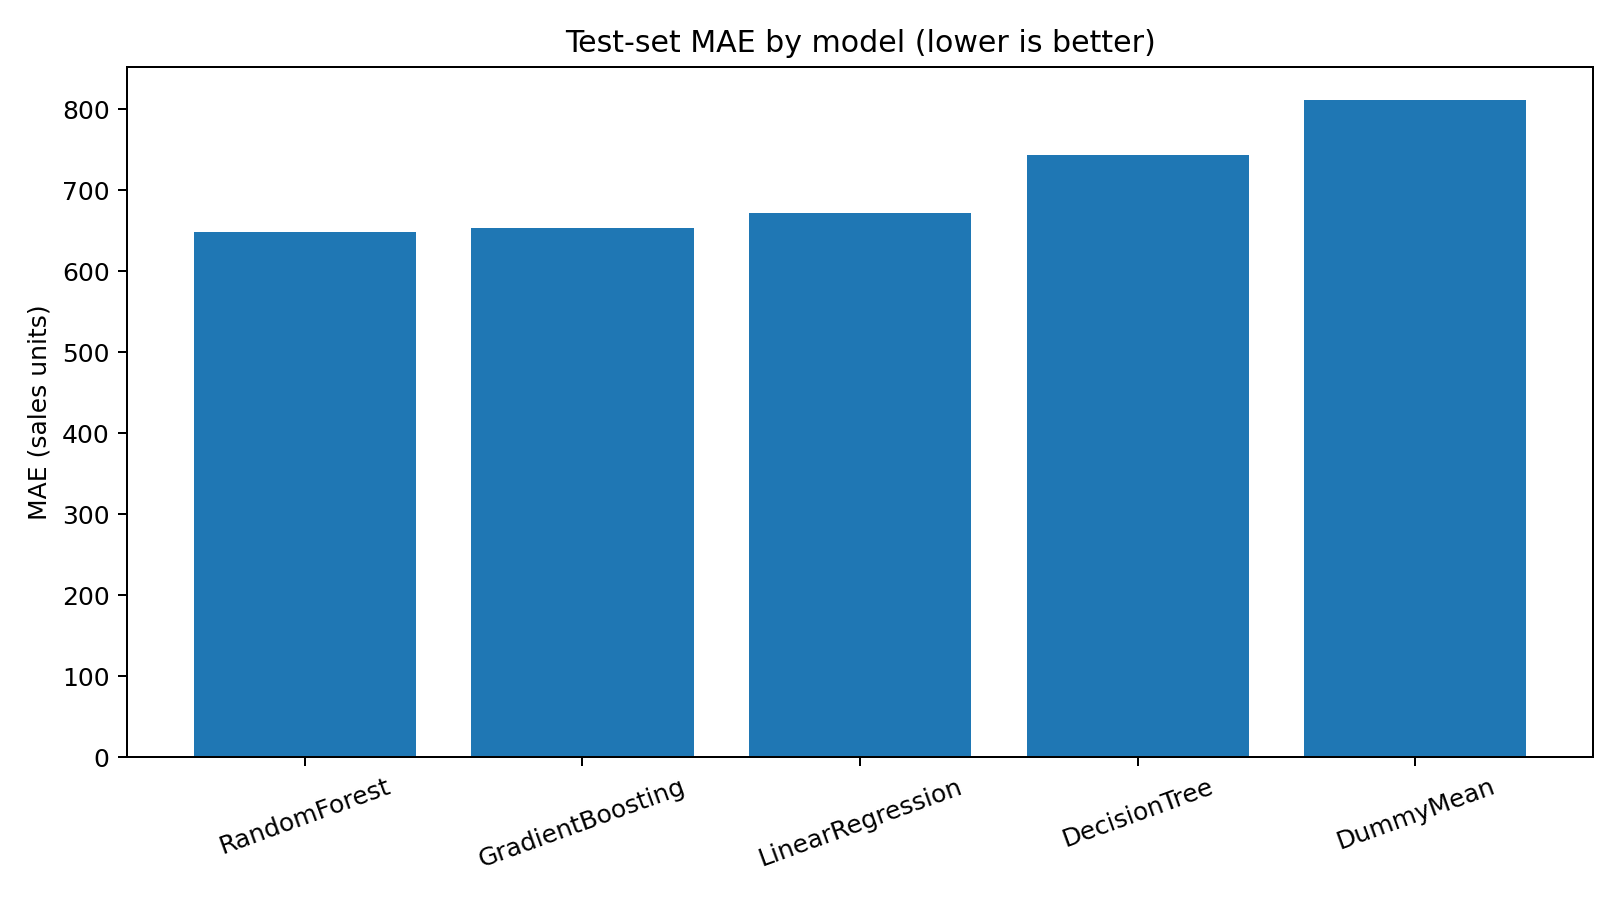

actual_vs_predicted.png


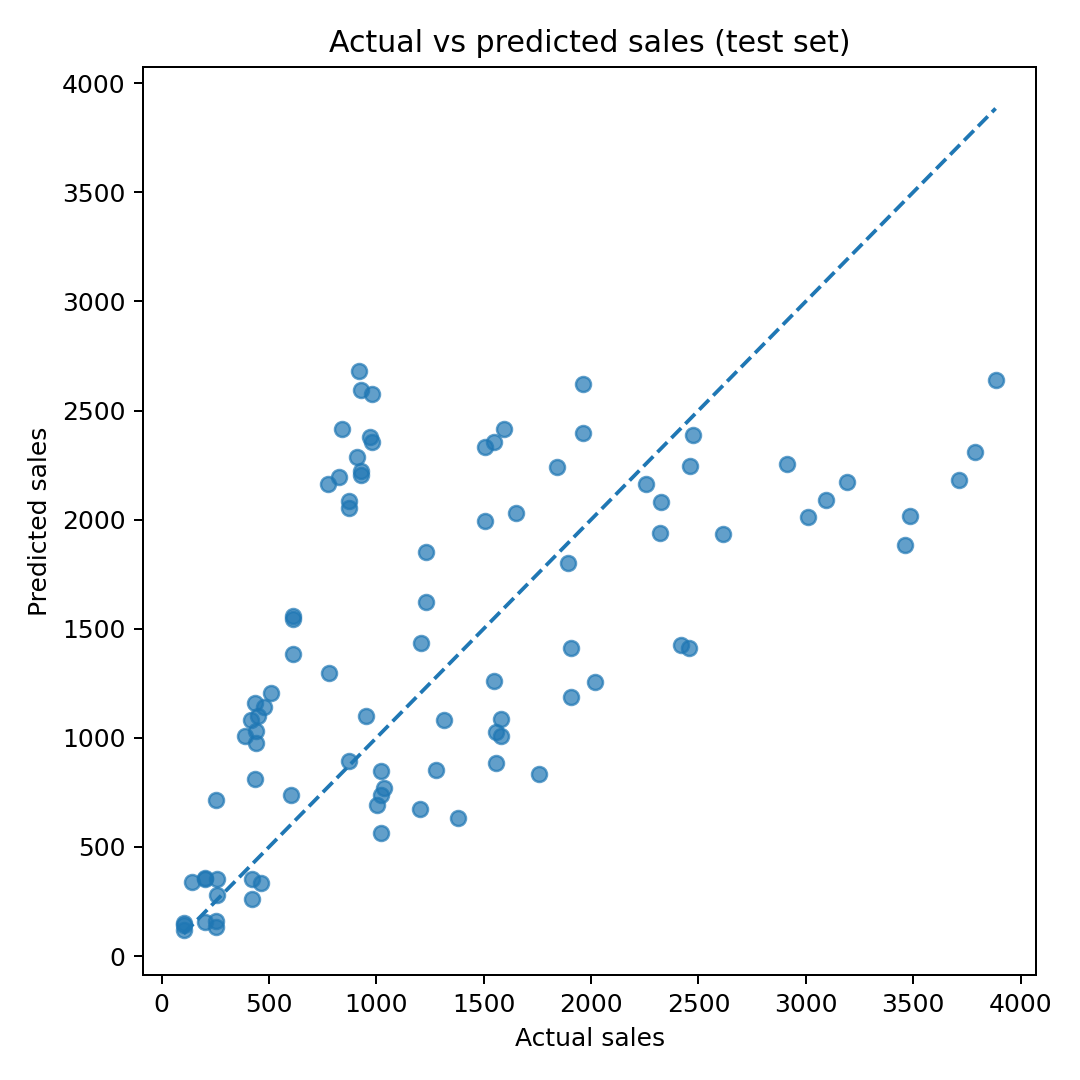

feature_importance.png


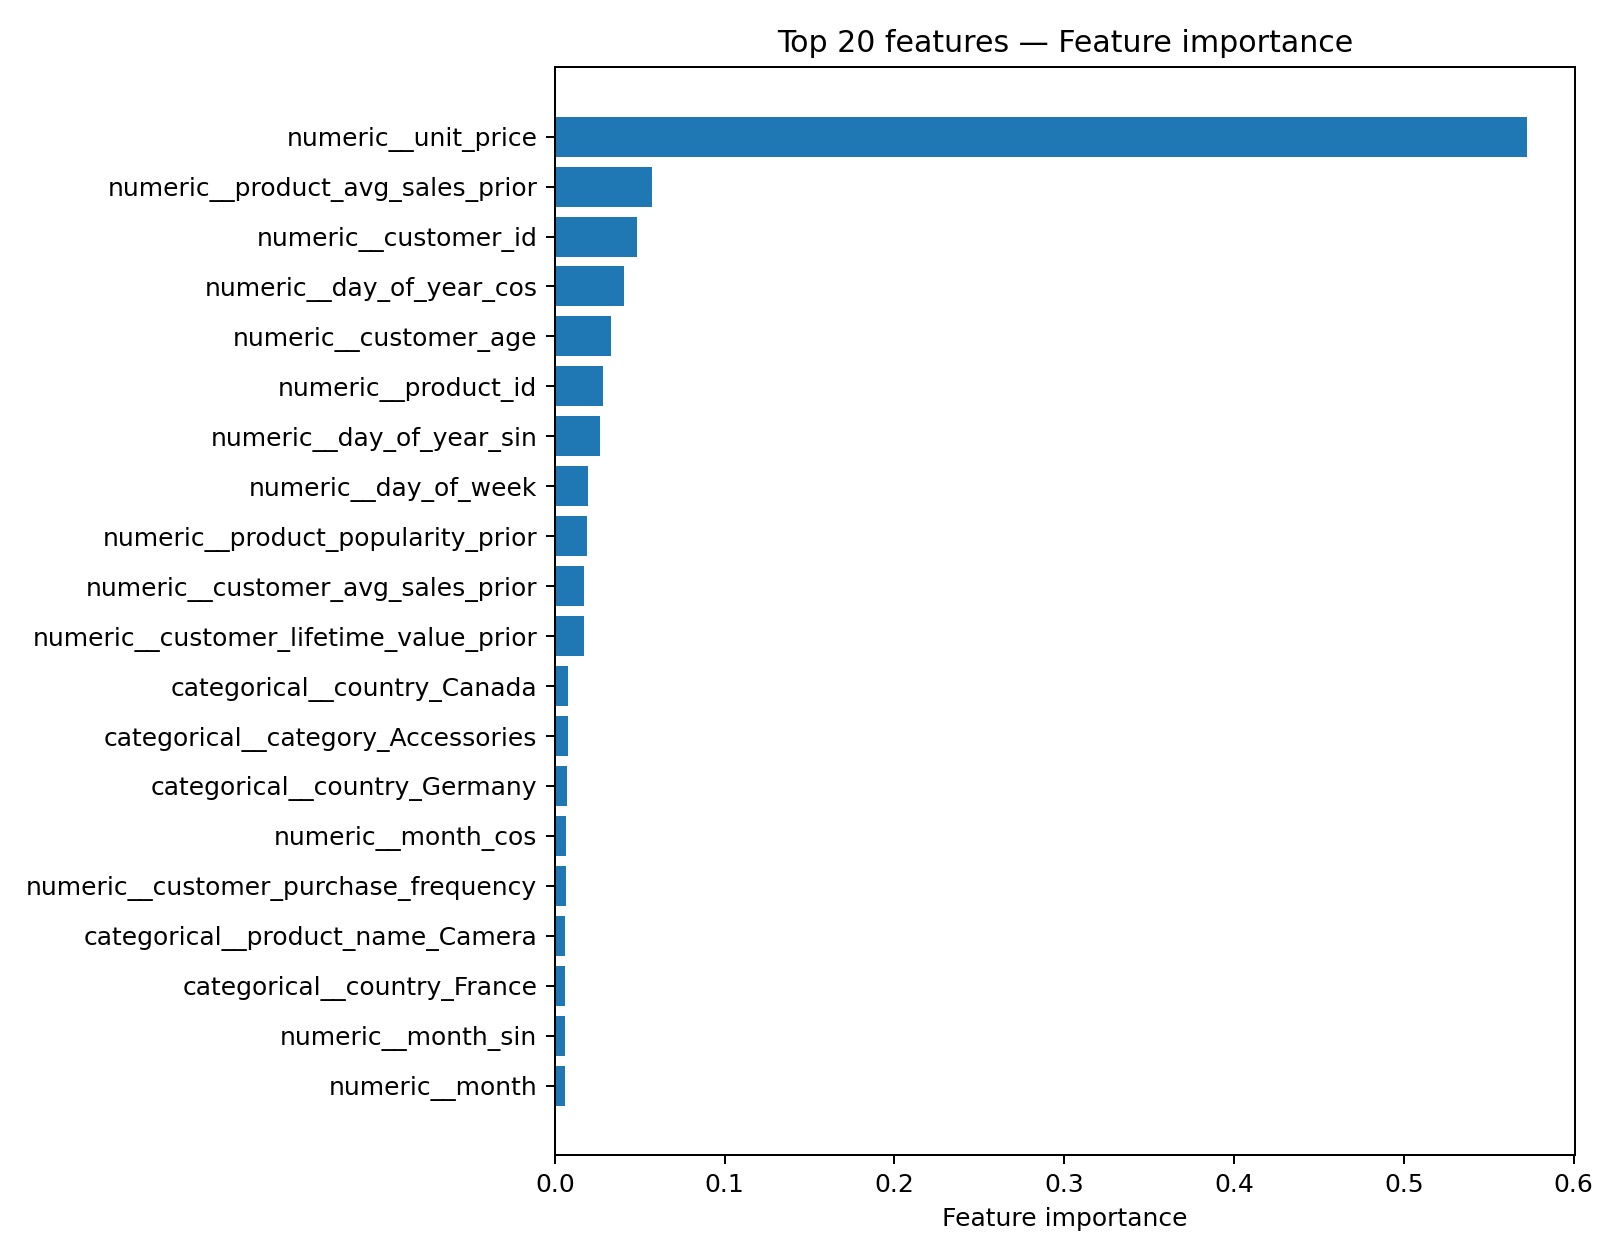

In [19]:
for figure_name in ["model_comparison_mae.png", "actual_vs_predicted.png", "feature_importance.png"]:
    figure_path = PROJECT_ROOT / "figures" / figure_name
    if figure_path.exists():
        print(figure_name)
        display(Image(filename=str(figure_path)))


### 8.2. Inspect Prediction Errors

`models/predictions.csv` lưu doanh thu thực tế, doanh thu dự đoán và sai số tuyệt đối của từng dòng trong Test.


In [20]:
predictions_path = PROJECT_ROOT / "models" / "predictions.csv"
predictions_df = pd.read_csv(predictions_path)
display(predictions_df.head(10))
print("Mean absolute error in saved predictions:", predictions_df["absolute_error"].mean())


,actual_sales,predicted_sales,absolute_error
0,416,1080.512354,664.512354
1,614,1544.542710,930.542710
2,1596,2415.622500,819.622500
3,260,281.911283,21.911283
4,921,2681.487848,1760.487848
5,204,355.285444,151.285444
6,141,340.421205,199.421205
7,1894,1800.822021,93.177979
8,2256,2163.845485,92.154515
9,3712,2180.716856,1531.283144


Mean absolute error in saved predictions: 648.8198162534472


## 9. Selected Model and Interpretation

Mô hình được chọn theo CV MAE thấp nhất, không phải theo một chỉ số Test thuận lợi nhất. Trong kết quả hiện có, Random Forest có CV MAE khoảng 611.95. Gradient Boosting có RMSE Test thấp hơn Random Forest; điều này cần được trình bày minh bạch khi giải thích kết quả.

R² Test của Random Forest khoảng 0.286, vì vậy hiệu quả hiện tại còn hạn chế và không nên diễn giải như mô hình đã sẵn sàng sử dụng trong môi trường kinh doanh thực tế.


In [21]:
summary_path = PROJECT_ROOT / "models" / "training_summary.json"
summary = json.loads(summary_path.read_text(encoding="utf-8"))
print("Selected model:", summary["best_model"])
print("Selection basis:", summary["selection_basis"])
print("Test metrics:")
display(pd.Series(summary["best_model_test_metrics"], name="value").to_frame())


Selected model: RandomForest
Selection basis: lowest time-series CV MAE
Test metrics:


,value
model,RandomForest
MAE,648.819816
MSE,649599.435181
RMSE,805.977317
R2,0.285659
CV_MAE,611.946608


## 10. Local Prediction Demo

Sau khi lưu model, `src/inference.py` tải bundle, sử dụng lịch sử Train và tạo Feature cho một giao dịch mới. `quantity` không được yêu cầu làm đầu vào.


In [22]:
sample_transaction = {
    "product_id": 9,
    "product_name": "Tablet",
    "category": "Electronics",
    "unit_price": 650,
    "customer_id": 101,
    "customer_age": 35,
    "customer_gender": "Female",
    "country": "Germany",
    "order_date": "2023-01-15",
}

predicted_sales = predict_sales(sample_transaction)
print("Sample transaction:")
print(sample_transaction)
print(f"Predicted sales revenue: {predicted_sales:,.2f}")


Sample transaction:
{'product_id': 9, 'product_name': 'Tablet', 'category': 'Electronics', 'unit_price': 650, 'customer_id': 101, 'customer_age': 35, 'customer_gender': 'Female', 'country': 'Germany', 'order_date': '2023-01-15'}
Predicted sales revenue: 1,495.01


## 11. Generate the Project Report

Module `src/report.py` tổng hợp các file kết quả thực tế và ghi báo cáo tại `doc/report.md`.


In [23]:
report_path = write_report()
print("Report saved to:", report_path)


Wrote /Users/momo/Downloads/ML_Lab2/doc/report.md
Report saved to: /Users/momo/Downloads/ML_Lab2/doc/report.md


## 12. Conclusion and Limitations

Notebook đã đi qua các bước chính của bài toán Regression: đọc dữ liệu, EDA, tiền xử lý, chronological split, feature engineering, tuning, evaluation, lưu model và inference.

Các hạn chế cần nhớ:

- Dataset có 500 giao dịch và chỉ bao phủ một năm.
- Không có trường marketing, advertising spend, rating/review hay nhãn ngày lễ chính thức.
- Cờ mùa cao điểm tháng 11–12 là proxy, không phải nhãn ngày lễ.
- `customer_lifetime_value_prior` là tổng doanh thu lịch sử đã quan sát, không phải CLV trọn đời.
- Random Forest có R² Test khoảng 0.286 trong kết quả đang lưu; cần thêm dữ liệu và kiểm nghiệm trước khi cân nhắc ứng dụng thực tế.
- Vì `quantity` bị loại khỏi Feature, mô hình không dự đoán doanh thu theo một số lượng đặt trước.

Để kiểm tra các test tự động, mở Terminal tại thư mục gốc và chạy:

```bash
pytest -q
```
